# DataVisualisation-TP2025 — TP4

[Teacher assignment](https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP4/TP4.md)

Run the cells from top to bottom. The required answers appear at the end. The repository also contains `EXPLICATION_AR.md` with the complete Arabic explanation. Data are included locally or downloaded from their original sources.

## Install the required libraries if needed

In [1]:
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'requests': 'requests', 'plotly': 'plotly', 'folium': 'folium', 'networkx': 'networkx'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


## 1. Imports and real World Bank data (2000–2023)

In [2]:
import json
from pathlib import Path
import textwrap

import folium
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.express as px
import requests
import seaborn as sns

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "results"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
INDICATORS = {"GDP_Per_Capita": "NY.GDP.PCAP.CD", "Life_Expectancy": "SP.DYN.LE00.IN",
              "Internet_Users_Pct": "IT.NET.USER.ZS", "Population": "SP.POP.TOTL"}

def get_json(url):
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    return response.json()

csv_path = DATA / "world_bank_2000_2023.csv"
if not csv_path.exists():
    metadata = get_json("https://api.worldbank.org/v2/country?format=json&per_page=400")[1]
    countries = {c["id"]: c for c in metadata if c["region"]["id"] != "NA"}
    records = {}
    for column, code in INDICATORS.items():
        observations = get_json(f"https://api.worldbank.org/v2/country/all/indicator/{code}?date=2000:2023&format=json&per_page=20000")[1]
        for item in observations:
            iso = item["countryiso3code"]
            if iso not in countries:
                continue
            key = (iso, int(item["date"]))
            c = countries[iso]
            records.setdefault(key, {"ISO3":iso, "Country":c["name"], "Region":c["region"]["value"],
                                     "Income_Group":c["incomeLevel"]["value"], "Year":key[1]})[column] = item["value"]
    pd.DataFrame(records.values()).sort_values(["ISO3", "Year"]).to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
for column in ["ISO3", "Country", "Region", "Income_Group"]:
    df[column] = df[column].str.strip()
df["Year"] = pd.to_numeric(df["Year"]).astype(int)
numeric = list(INDICATORS)
for column in numeric:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df = df.drop_duplicates(["ISO3", "Year"]).sort_values(["ISO3", "Year"])
latest_year = int(df["Year"].max())
latest = df.loc[df["Year"] == latest_year].copy()
# Remove only the missing values needed by each analysis; do not invent values.
comparative = latest.dropna(subset=["GDP_Per_Capita", "Life_Expectancy", "Population"])
comparative = comparative.loc[(comparative["GDP_Per_Capita"] > 0) & (comparative["Population"] > 0)]
complete = latest.dropna(subset=numeric)
print(df.head().to_string(index=False))
print("Missing values:\n", df[numeric].isna().sum())
print(f"{len(df)} country-year rows; latest selected year: {latest_year}; comparative countries: {len(comparative)}")

ISO3 Country                    Region Income_Group  Year  GDP_Per_Capita  Life_Expectancy  Internet_Users_Pct  Population
 ABW   Aruba Latin America & Caribbean  High income  2000    20681.023027           72.939           15.442823       90588
 ABW   Aruba Latin America & Caribbean  High income  2001    20740.132583           73.044           17.100000       91439
 ABW   Aruba Latin America & Caribbean  High income  2002    21307.248251           73.135           18.800000       92074
 ABW   Aruba Latin America & Caribbean  High income  2003    21949.485996           73.236           20.800000       93128
 ABW   Aruba Latin America & Caribbean  High income  2004    23700.631990           73.223           23.000000       95138
Missing values:
 GDP_Per_Capita        166
Life_Expectancy         0
Internet_Users_Pct    500
Population              0
dtype: int64
5208 country-year rows; latest selected year: 2023; comparative countries: 204


## 2. Scatter, population bubble and two-dimensional density charts

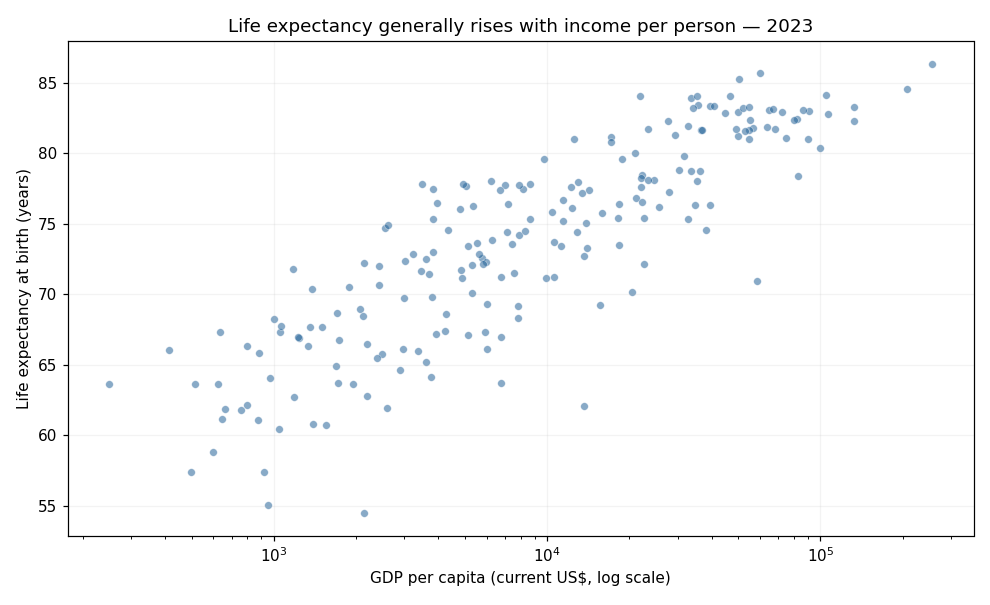

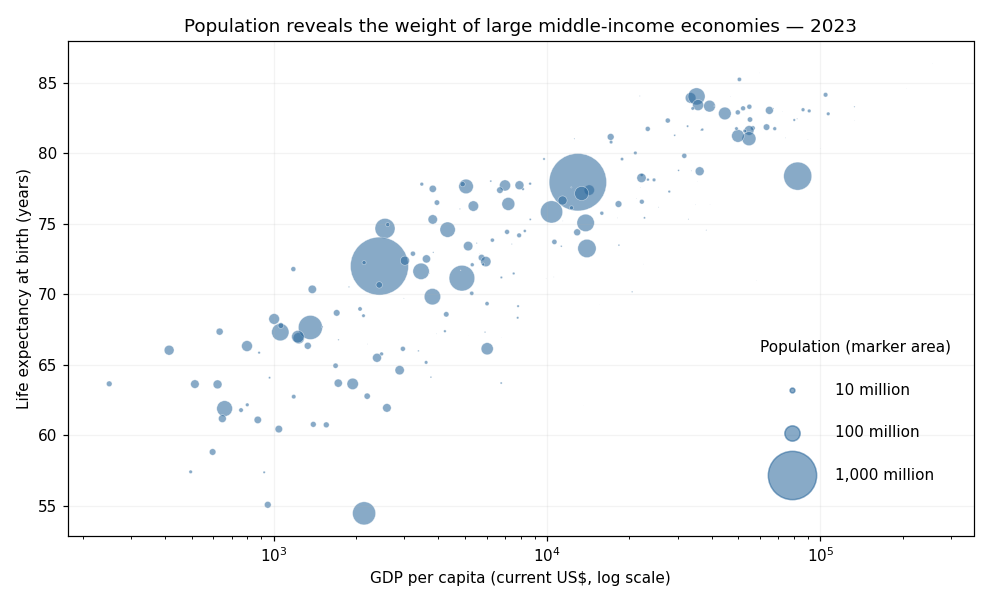

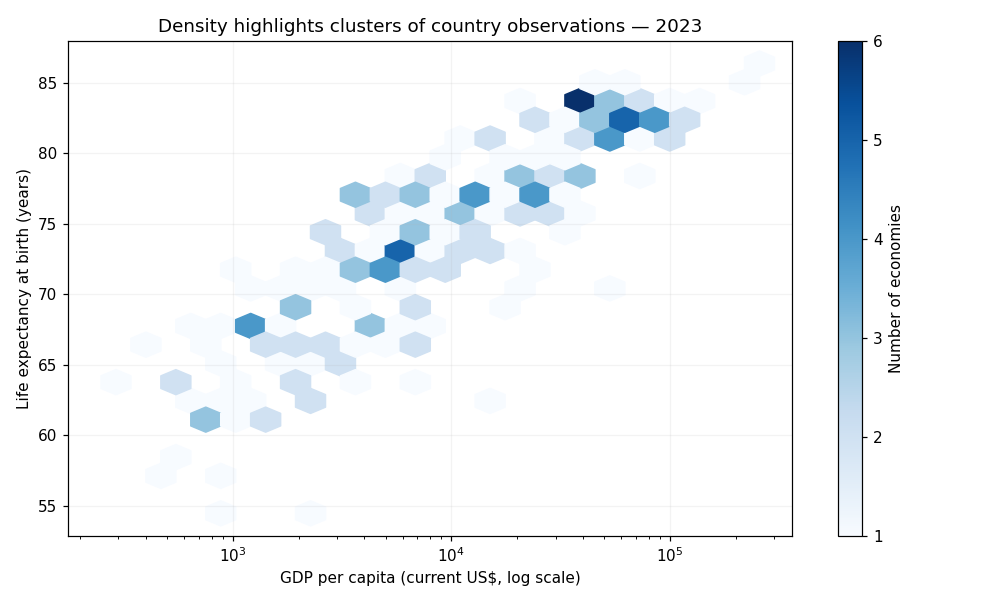

In [3]:
for name, kind in [("01_scatter", "scatter"), ("02_bubble", "bubble"), ("03_density", "density")]:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    if kind == "density":
        cells = ax.hexbin(comparative["GDP_Per_Capita"], comparative["Life_Expectancy"],
                          xscale="log", gridsize=22, mincnt=1, cmap="Blues")
        fig.colorbar(cells, ax=ax, label="Number of economies")
        title = "Density highlights clusters of country observations"
    else:
        # Matplotlib's s is marker AREA, so population determines area, not radius.
        size = comparative["Population"] / 1_000_000 if kind == "bubble" else 25
        ax.scatter(comparative["GDP_Per_Capita"], comparative["Life_Expectancy"],
                   s=size, alpha=0.55, color="#27659a", edgecolor="white", linewidth=0.4)
        ax.set_xscale("log")
        title = "Population reveals the weight of large middle-income economies" if kind == "bubble" else "Life expectancy generally rises with income per person"
        if kind == "bubble":
            for millions in [10, 100, 1000]:
                ax.scatter([], [], s=millions, color="#27659a", alpha=0.55, label=f"{millions:,} million")
            ax.legend(title="Population (marker area)", frameon=False, loc="lower right",
                      bbox_to_anchor=(0.99, 0.08), labelspacing=1.8, handletextpad=1.8)
    ax.set(title=f"{title} — {latest_year}", xlabel="GDP per capita (current US$, log scale)",
           ylabel="Life expectancy at birth (years)")
    ax.grid(alpha=0.15)
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=140)
    plt.show()
    plt.close(fig)

## 3. Pearson heatmap, using the same complete-country sample for every pair

Strongest pair: ('Life_Expectancy', 'Internet_Users_Pct') 0.8065188389886584
Population relationships:
 GDP_Per_Capita       -0.056729
Life_Expectancy       0.002715
Internet_Users_Pct   -0.004329
Name: Population, dtype: float64


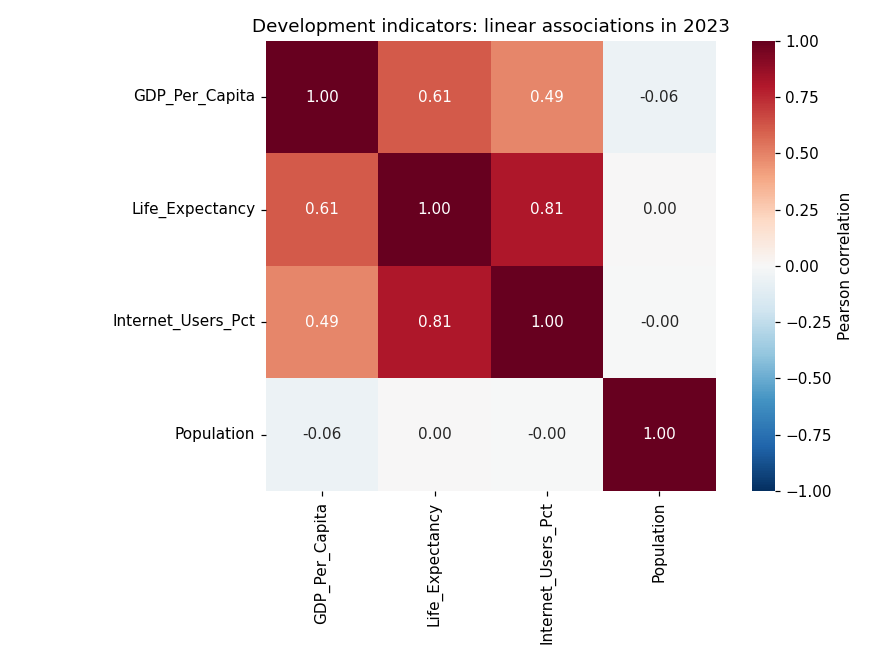

In [4]:
correlation = complete[numeric].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title(f"Development indicators: linear associations in {latest_year}")
fig.tight_layout()
fig.savefig(OUT / "04_correlation_heatmap.png", dpi=140)
plt.show()
plt.close(fig)
correlation.to_csv(OUT / "correlation.csv")
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
strongest_pair = pairs.abs().idxmax()
strongest_r = float(pairs.loc[strongest_pair])
print("Strongest pair:", strongest_pair, strongest_r)
print("Population relationships:\n", correlation["Population"].drop("Population"))

## 4. Interactive GDP trends: Germany (high income) and Algeria (developing)

In [5]:
trend = df.loc[df["ISO3"].isin(["DEU", "DZA"])].dropna(subset=["GDP_Per_Capita"])
line_chart = px.line(trend, x="Year", y="GDP_Per_Capita", color="Country",
                     title="GDP per capita over time: Germany and Algeria (2000–2023)",
                     labels={"GDP_Per_Capita": "GDP per capita (current US$)"},
                     hover_data={"Income_Group": True})
line_chart.update_layout(dragmode="pan", hovermode="x unified")
line_chart.write_html(OUT / "05_interactive_gdp.html", include_plotlyjs=True,
                      config={"scrollZoom": True, "displayModeBar": True})
line_chart.show(config={"scrollZoom": True})

Interactive GDP chart; also saved as results/05_interactive_gdp.html

## 5. Interactive Folium choropleth for the latest year in our dataset

In [6]:
geo_path = DATA / "countries.geo.json"
if not geo_path.exists():
    boundaries = get_json("https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json")
    geo_path.write_text(json.dumps(boundaries), encoding="utf-8")
boundaries = json.loads(geo_path.read_text(encoding="utf-8"))
map_data = latest.dropna(subset=["Life_Expectancy"])
lookup = map_data.set_index("ISO3")
for feature in boundaries["features"]:
    iso = feature["id"]
    available = iso in lookup.index
    feature["properties"]["Country"] = lookup.loc[iso, "Country"] if available else feature["properties"]["name"]
    feature["properties"]["Life_Expectancy"] = round(float(lookup.loc[iso, "Life_Expectancy"]), 1) if available else "No matched data"
world_map = folium.Map(location=[20, 0], zoom_start=2, tiles="CartoDB positron")
choropleth = folium.Choropleth(geo_data=boundaries, data=map_data,
    columns=["ISO3", "Life_Expectancy"], key_on="feature.id", fill_color="YlGnBu",
    fill_opacity=0.8, line_opacity=0.3, nan_fill_color="lightgray",
    legend_name=f"Life expectancy at birth, {latest_year} (years)").add_to(world_map)
folium.GeoJsonTooltip(fields=["Country", "Life_Expectancy"],
                      aliases=["Country", "Life expectancy (years)"]).add_to(choropleth.geojson)
world_map.save(str(OUT / "06_life_expectancy_map.html"))
from IPython.display import display
display(world_map)

C:\Users\chikh\Desktop\UNIV\DataVisualisation-TP2025\.task-tools\packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 6. NetworkX hierarchy: all World Bank economies, with ISO3 country labels

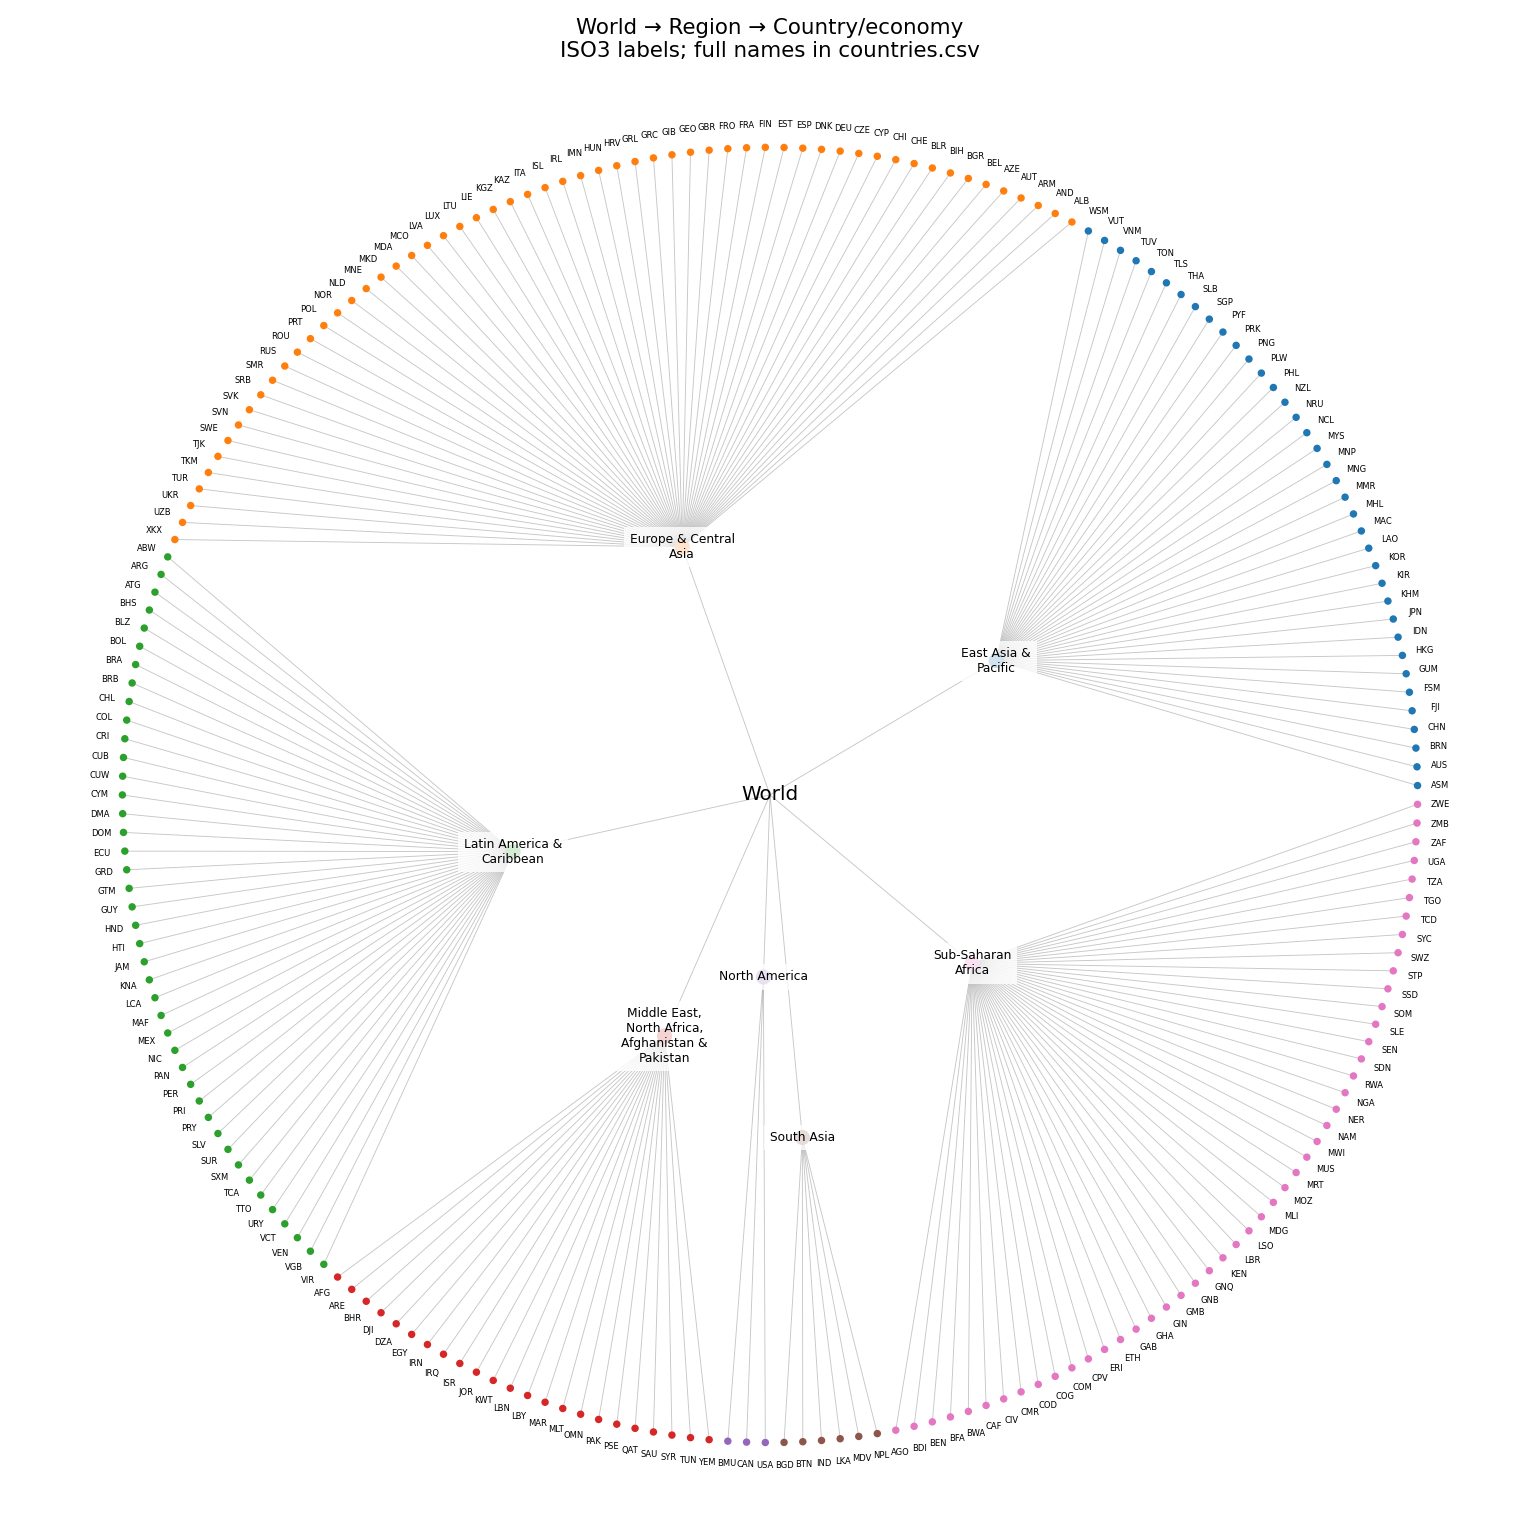

In [7]:
graph = nx.DiGraph()
graph.add_node("World")
regions = sorted(latest["Region"].unique())
positions = {"World": (0, 0)}
region_colors = plt.get_cmap("tab10")
country_colors = []
country_order = []
offset = 0
total = len(latest)
for index, region in enumerate(regions):
    group = latest.loc[latest["Region"] == region].sort_values("ISO3")
    graph.add_edge("World", region)
    center_angle = 2 * np.pi * (offset + len(group) / 2) / total
    # Separate the labels of the two neighboring small regional groups.
    radius = 0.45 if region == "North America" else 0.85 if region == "South Asia" else 0.65
    positions[region] = (radius * np.cos(center_angle), radius * np.sin(center_angle))
    for number, row in enumerate(group.itertuples()):
        graph.add_edge(region, row.ISO3)
        angle = 2 * np.pi * (offset + number + 0.5) / total
        positions[row.ISO3] = (1.6 * np.cos(angle), 1.6 * np.sin(angle))
        country_order.append(row.ISO3)
        country_colors.append(region_colors(index))
    offset += len(group)
fig, ax = plt.subplots(figsize=(14, 14))
nx.draw_networkx_edges(graph, positions, ax=ax, arrows=False, alpha=0.22, width=0.6)
nx.draw_networkx_nodes(graph, positions, nodelist=country_order, node_size=15, node_color=country_colors, ax=ax)
nx.draw_networkx_nodes(graph, positions, nodelist=regions, node_size=80,
                       node_color=[region_colors(i) for i in range(len(regions))], ax=ax)
nx.draw_networkx_labels(graph, positions, labels={"World": "World"}, font_size=13, ax=ax)
for region in regions:
    x, y = positions[region]
    ax.text(x, y, textwrap.fill(region, 17), ha="center", va="center", fontsize=8,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})
for iso in country_order:
    x, y = positions[iso]
    ax.text(x * 1.035, y * 1.035, iso, ha="center", va="center", fontsize=5.5)
ax.set_title("World → Region → Country/economy\nISO3 labels; full names in countries.csv", fontsize=14)
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.8, 1.8)
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "07_regional_hierarchy.png", dpi=150)
plt.show()
plt.close(fig)
latest[["ISO3", "Country", "Region"]].to_csv(OUT / "countries.csv", index=False)

## 7. Required comparisons and interpretation

In [8]:
population_text = "\n".join(f"- Population vs {col}: r = {correlation.loc['Population', col]:.3f}."
                            for col in numeric if col != "Population")
report = f"""# TP4 — Answers

## Data and cleaning
World Bank WDI, 2000–2023; {len(df)} country-year rows. Aggregate regions are
excluded. The latest year **within this selected dataset** is {latest_year},
not a claim about the newest year currently published by the World Bank.
Economies include some territories as classified by the source.
Numerical types are standardized, duplicate country-years removed and missing
values excluded only for analyses that need them. Comparative charts use
{len(comparative)} complete GDP/life/population economies; the heatmap uses
{len(complete)} economies complete on all four indicators. No values are imputed.
The assignment labels its variable GDP_Per_Capita but gives NY.GDP.MKTP.CD
(total GDP). We use **NY.GDP.PCAP.CD**, the correct per-person indicator.

## Comparative chart choice
| Chart | Advantage | Disadvantage | Best use |
|---|---|---|---|
| Scatter | Shows the income/life relationship clearly | Every country has equal visual weight | Two-variable relationship |
| Bubble | Adds population as marker area | Overlap and area comparisons can be difficult | Population scale and impact |
| Density | Reveals concentrations of countries | Hides individual identities and population weights | Observation clusters |

Choose the **bubble chart** for the requested message. The horizontal spread
and vertical positions let us compare life expectancy among poorer economies;
the large areas identify populous middle-income economies. Population is
encoded as area, not radius. Logarithmic GDP spreads out low-income observations.
Density counts countries rather than people, so cannot communicate population
burden by itself. A bubble plot helps explain weights but does not itself
calculate the global population-weighted average or establish causation.

## Pearson correlations
The strongest absolute pair is **{strongest_pair[0]} / {strongest_pair[1]}**,
r = **{strongest_r:.3f}**. A plausible hypothesis is that economic development,
education, infrastructure and public services jointly relate to income,
connectivity and health; this is an interpretation, not a causal finding.
{population_text}
Population is total country size, whereas GDP is per person and internet use
is a percentage. Size alone therefore need not have a strong linear association
with development. Skewed population/GDP values and a few large economies affect
Pearson's measure; the heatmap uses raw values, unlike the log-scaled plot axis.

## Interactive tools and hierarchy
Germany and Algeria provide high-income and developing-country GDP trends;
hover, pan, zoom and the toolbar are enabled. Current-dollar trends include
price and exchange-rate effects and are not inflation-adjusted growth measures.
The Folium map displays {latest_year} life expectancy and country tooltips.
Gray means absent or unmatched data; historical boundary differences and ISO3
coverage can leave some economies unmapped. HTML files open in a browser.
The NetworkX graph includes all {len(latest)} selected economies under their
World Bank regions; ISO3 labels keep the full graph legible, with a names CSV.
Membership edges describe geography, not actual economic flows.

To model economic relationships, use countries as nodes and directed trade,
FDI, remittance or supply-chain links as edges, weighted by value/volume and
dated by year. This requires bilateral partner data, common country IDs,
currency/unit definitions and reporting dates. Regional membership alone does
not supply these transactions. No optional node-size or Altair bonus is added.

Sources: https://data.worldbank.org/indicator/NY.GDP.PCAP.CD (WDI, CC BY 4.0);
boundaries: https://github.com/johan/world.geo.json (public-domain repository).
Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP4/TP4.md
"""
(OUT / "REPORT.md").write_text(report, encoding="utf-8")
print("Saved required visualizations and answers in", OUT)

Saved required visualizations and answers in C:\Users\chikh\Desktop\UNIV\DataVisualisation-TP2025\DataVisualisation-TP2025--TP4\results


## Required written answers

In [9]:
from IPython.display import Markdown, display
display(Markdown((OUT / "REPORT.md").read_text(encoding="utf-8")))

# TP4 — Answers

## Data and cleaning
World Bank WDI, 2000–2023; 5208 country-year rows. Aggregate regions are
excluded. The latest year **within this selected dataset** is 2023,
not a claim about the newest year currently published by the World Bank.
Economies include some territories as classified by the source.
Numerical types are standardized, duplicate country-years removed and missing
values excluded only for analyses that need them. Comparative charts use
204 complete GDP/life/population economies; the heatmap uses
180 economies complete on all four indicators. No values are imputed.
The assignment labels its variable GDP_Per_Capita but gives NY.GDP.MKTP.CD
(total GDP). We use **NY.GDP.PCAP.CD**, the correct per-person indicator.

## Comparative chart choice
| Chart | Advantage | Disadvantage | Best use |
|---|---|---|---|
| Scatter | Shows the income/life relationship clearly | Every country has equal visual weight | Two-variable relationship |
| Bubble | Adds population as marker area | Overlap and area comparisons can be difficult | Population scale and impact |
| Density | Reveals concentrations of countries | Hides individual identities and population weights | Observation clusters |

Choose the **bubble chart** for the requested message. The horizontal spread
and vertical positions let us compare life expectancy among poorer economies;
the large areas identify populous middle-income economies. Population is
encoded as area, not radius. Logarithmic GDP spreads out low-income observations.
Density counts countries rather than people, so cannot communicate population
burden by itself. A bubble plot helps explain weights but does not itself
calculate the global population-weighted average or establish causation.

## Pearson correlations
The strongest absolute pair is **Life_Expectancy / Internet_Users_Pct**,
r = **0.807**. A plausible hypothesis is that economic development,
education, infrastructure and public services jointly relate to income,
connectivity and health; this is an interpretation, not a causal finding.
- Population vs GDP_Per_Capita: r = -0.057.
- Population vs Life_Expectancy: r = 0.003.
- Population vs Internet_Users_Pct: r = -0.004.
Population is total country size, whereas GDP is per person and internet use
is a percentage. Size alone therefore need not have a strong linear association
with development. Skewed population/GDP values and a few large economies affect
Pearson's measure; the heatmap uses raw values, unlike the log-scaled plot axis.

## Interactive tools and hierarchy
Germany and Algeria provide high-income and developing-country GDP trends;
hover, pan, zoom and the toolbar are enabled. Current-dollar trends include
price and exchange-rate effects and are not inflation-adjusted growth measures.
The Folium map displays 2023 life expectancy and country tooltips.
Gray means absent or unmatched data; historical boundary differences and ISO3
coverage can leave some economies unmapped. HTML files open in a browser.
The NetworkX graph includes all 217 selected economies under their
World Bank regions; ISO3 labels keep the full graph legible, with a names CSV.
Membership edges describe geography, not actual economic flows.

To model economic relationships, use countries as nodes and directed trade,
FDI, remittance or supply-chain links as edges, weighted by value/volume and
dated by year. This requires bilateral partner data, common country IDs,
currency/unit definitions and reporting dates. Regional membership alone does
not supply these transactions. No optional node-size or Altair bonus is added.

Sources: https://data.worldbank.org/indicator/NY.GDP.PCAP.CD (WDI, CC BY 4.0);
boundaries: https://github.com/johan/world.geo.json (public-domain repository).
Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP4/TP4.md
